In [1]:
# import libraries
import matplotlib.pyplot as plt
import numpy as np

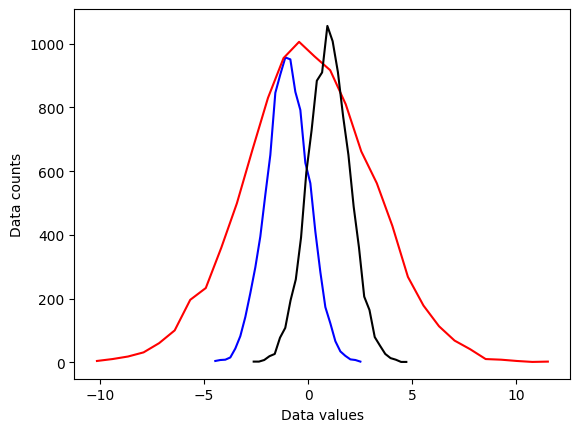

In [2]:
## create some data distributions

# the distributions
N = 10001   # number of data points
nbins = 30  # number of histogram bins

d1 = np.random.randn(N) - 1
d2 = 3*np.random.randn(N)
d3 = np.random.randn(N) + 1

# need their histograms
y1,x1 = np.histogram(d1,nbins)
x1 = (x1[1:]+x1[:-1])/2

y2,x2 = np.histogram(d2,nbins)
x2 = (x2[1:]+x2[:-1])/2

y3,x3 = np.histogram(d3,nbins)
x3 = (x3[1:]+x3[:-1])/2


# plot them
plt.plot(x1,y1,'b')
plt.plot(x2,y2,'r')
plt.plot(x3,y3,'k')

plt.xlabel('Data values')
plt.ylabel('Data counts')
plt.show()

In [3]:
# side note:

meanval = 10.2
stdval  = 7.5
numsamp = 123

# this
np.random.normal(meanval,stdval,numsamp)

# is equivalent to
np.random.randn(numsamp)*stdval + meanval

array([17.62111993, 17.19980006, 15.38635315, 23.77408753,  6.46782852,
       13.09306919, -7.6557085 ,  2.08812519,  5.27462078,  6.94717807,
       10.78112282, 20.2673238 ,  6.98690831,  7.7727067 ,  7.00945971,
        0.82343412, 16.71286781,  3.3503933 ,  4.60138454, 15.66529428,
       11.95789158,  9.34031494,  8.95637762, 27.14309322,  3.3218793 ,
       15.23233299,  5.62860594,  5.93106395,  7.60892035,  4.71424223,
       -1.43774479, 23.66094021,  7.06236897, 13.52671386, 10.59399304,
       21.51620849, -1.30451832,  6.28651196,  1.80819697, 11.00365777,
       18.67928091, 24.17548083,  6.63353335, 23.74999796,  6.08280724,
        3.05709281, 10.13619954,  6.6024377 , -0.52150417, -2.2857651 ,
       -2.0305009 , 20.33930955, 11.55314945, 17.27234977, 16.48367343,
        5.43283873,  3.50558349, 12.84609376,  4.13613166, 24.02680591,
        6.47228893, 10.55288323,  1.36439249, 16.36054099,  6.24912272,
        6.97142793,  8.72575796, 16.61609847,  8.93758058, 14.33

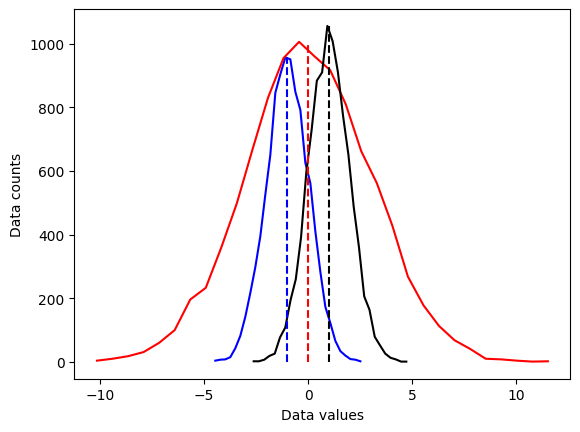

In [4]:
## overlay the mean

# compute the means
mean_d1 = sum(d1) / len(d1)
mean_d2 = np.mean(d2)
mean_d3 = np.mean(d3)

# plot them
plt.plot(x1,y1,'b', x2,y2,'r', x3,y3,'k')
plt.plot([mean_d1,mean_d1],[0,max(y1)],'b--')
plt.plot([mean_d2,mean_d2],[0,max(y2)],'r--')
plt.plot([mean_d3,mean_d3],[0,max(y3)],'k--')

plt.xlabel('Data values')
plt.ylabel('Data counts')
plt.show()

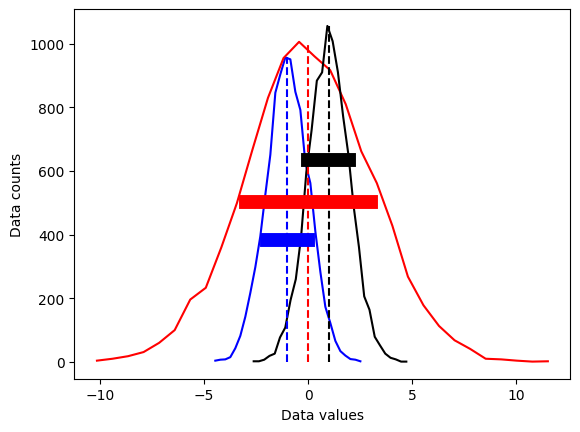

In [5]:
## now for the standard deviation

# initialize
stds = np.zeros(3)

# compute standard deviations
stds[0] = np.std(d1,ddof=1)
stds[1] = np.std(d2,ddof=1)
stds[2] = np.std(d3,ddof=1)


# same plot as earlier
plt.plot(x1,y1,'b', x2,y2,'r', x3,y3,'k')
plt.plot([mean_d1,mean_d1],[0,max(y1)],'b--', [mean_d2,mean_d2],[0,max(y2)],'r--',[mean_d3,mean_d3],[0,max(y3)],'k--')

# now add stds
plt.plot([mean_d1-stds[0],mean_d1+stds[0]],[.4*max(y1),.4*max(y1)],'b',linewidth=10)
plt.plot([mean_d2-stds[1],mean_d2+stds[1]],[.5*max(y2),.5*max(y2)],'r',linewidth=10)
plt.plot([mean_d3-stds[2],mean_d3+stds[2]],[.6*max(y3),.6*max(y3)],'k',linewidth=10)

plt.xlabel('Data values')
plt.ylabel('Data counts')
plt.show()

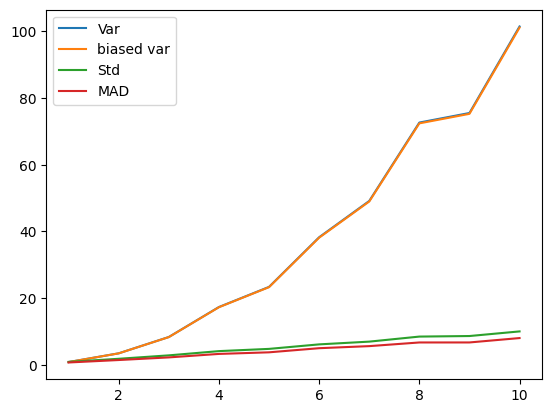

In [6]:
## different variance measures

variances = np.arange(1,11)
N = 300

varmeasures = np.zeros((4,len(variances)))

for i in range(len(variances)):

    # create data and mean-center
    data = np.random.randn(N) * variances[i]
    datacent = data - np.mean(data)

    # variance
    varmeasures[0,i] = sum(datacent**2) / (N-1)

    # "biased" variance
    varmeasures[1,i] = sum(datacent**2) / N

    # standard deviation
    varmeasures[2,i] = np.sqrt( sum(datacent**2) / (N-1) )

    # MAD (mean absolute difference)
    varmeasures[3,i] = sum(abs(datacent)) / (N-1)


# show them!
plt.plot(variances,varmeasures.T)
plt.legend(('Var','biased var','Std','MAD'))
plt.show()

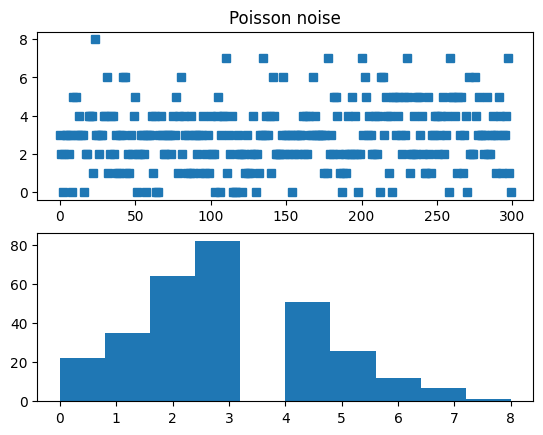

In [7]:
## Fano factor and coefficient of variation (CV)

# need positive-valued data (why?)
data = np.random.poisson(3,300)  # "Poisson noise"

fig,ax = plt.subplots(2,1)
ax[0].plot(data,'s')
ax[0].set_title('Poisson noise')

ax[1].hist(data)
plt.show()

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_747/2263249198.py:24: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$')


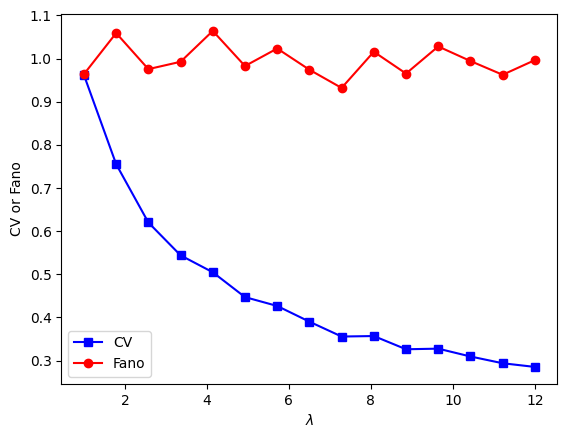

In [8]:
## compute fano factor and CV for a range of lambda parameters

# list of parameters
lambdas = np.linspace(1,12,15)

# initialize output vectors
fano = np.zeros(len(lambdas))
cv   = np.zeros(len(lambdas))

for li in range(len(lambdas)):

    # generate new data
    data = np.random.poisson(lambdas[li],1000)

    # compute the metrics
    cv[li]   = np.std(data) / np.mean(data) # need ddof=1 here?
    fano[li] = np.var(data) / np.mean(data)


# and plot
plt.plot(lambdas,cv,'bs-')
plt.plot(lambdas,fano,'ro-')
plt.legend(('CV','Fano'))
plt.xlabel('$\lambda$')
plt.ylabel('CV or Fano')
plt.show()